---
# <font color="#CA3532">Deep Learning Fundamentals and Basic Tools (2026/2027) - Final project</font>
---


In this project you will implement and compare four deep-learning architectures for multiclass human activity recognition:

- Deep Neural Network (DNN)
- Recurrent Neural Network (RNN)
- 1D Convolutional Neural Network (CNN)
- Long Short-Term Memory Network (LSTM)

You will work with the **UCI Human Activity Recognition Using Smartphones (UCI HAR)** dataset.

You must compare predictive performance, class-level errors, convergence, model complexity, training time, inference time, and stability across repeated runs.

## <font color="#3279ca">Generative-AI Policy</font>


The use of any generative-AI or Large Language Model (LLM) to generate, complete, rewrite, or substantially assist with the code, experiments, analysis, or written answers for this project is **not permitted**.

**Work generated using LLM assistance will be treated as plagiarism. If it is the case, the corresponding project code will not be evaluated and the student will receive no credit for that work.**


## <font color="#3279ca">Project report</font>

You must write a project report explaning the following points;

- individual functions and model layers;
- tensor dimensions;
- the training procedure;
- suugest an alternative for part of your implementation;
- interpret results, confusion matrices, and all metrics;
- explain your conclusions.

Do not submit code or analysis that you cannot explain.

### <font color="#0da432">Imports</font>

In [1]:

import json
import sys
import importlib
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

if "src.models" in sys.modules:
    del sys.modules["src.models"]

import src.models
importlib.reload(src.models)
import time
import platform
from src.utils import set_seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from src.models import (
    DNNClassifier,
    RNNClassifier,
    CNNClassifier,
    LSTMClassifier,
)
from src.training import fit
from src.evaluation import (
    evaluate_model,
    count_parameters,
    measure_inference_time,
)

In [2]:
# Guarda cada figura en resultsYago/figures al hacer plt.show()
import re
PROJECT_ROOT = Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "resultsYago"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
_show = plt.show

def _show_and_save(*args, **kwargs):
    fig = plt.gcf()
    title = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figure")
    name = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _show_and_save


### <font color="#0da432">Dataset</font>

In [3]:
train_df = pd.read_csv("../data/final_project/train.csv")
test_df = pd.read_csv("../data/final_project/test.csv")

TARGET = "Activity"
DROP_COLUMNS = ["subject", TARGET]

X = train_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)
X_test = test_df.drop(columns=DROP_COLUMNS).to_numpy(dtype=np.float32)

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(train_df[TARGET]).astype(np.int64)
y_test = label_encoder.transform(test_df[TARGET]).astype(np.int64)

class_names = label_encoder.classes_

# Create validation split from training data
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_df["subject"])
)

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

# Verify subjects do not overlap
train_subjects = set(train_df.iloc[train_idx]["subject"])
val_subjects = set(train_df.iloc[val_idx]["subject"])

assert train_subjects.isdisjoint(val_subjects), \
    "Subject leakage detected!"

# Scale using ONLY training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Dataset dimensions
n_features = X_train.shape[1]
n_classes = len(class_names)

sequence_length = n_features

# DNN
X_train_dnn = X_train
X_val_dnn = X_val
X_test_dnn = X_test

# RNN / LSTM
# Shape: (samples, sequence_length, features_per_step)
X_train_rnn = X_train[..., np.newaxis]
X_val_rnn = X_val[..., np.newaxis]
X_test_rnn = X_test[..., np.newaxis]

X_train_lstm = X_train[..., np.newaxis]
X_val_lstm = X_val[..., np.newaxis]
X_test_lstm = X_test[..., np.newaxis]

# CNN - TensorFlow / Keras Conv1D
# Shape: (samples, length, channels)
X_train_cnn_tf = X_train[..., np.newaxis]
X_val_cnn_tf = X_val[..., np.newaxis]
X_test_cnn_tf = X_test[..., np.newaxis]

# CNN - PyTorch Conv1d
# Shape: (samples, channels, length)
X_train_cnn_torch = X_train[:, np.newaxis, :]
X_val_cnn_torch = X_val[:, np.newaxis, :]
X_test_cnn_torch = X_test[:, np.newaxis, :]

# Display dataset information
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("Number of features:", n_features)
print("Number of classes:", n_classes)

print("Training subjects:", len(train_subjects))
print("Validation subjects:", len(val_subjects))
print("Subject overlap:", len(train_subjects & val_subjects))


Training shape: (5551, 561)
Validation shape: (1801, 561)
Test shape: (2947, 561)
Number of features: 561
Number of classes: 6
Training subjects: 16
Validation subjects: 5
Subject overlap: 0


## <font color="#0da432">Implementation Requirements</font>
rgb(18, 13, 164)
You must implement the backend yourself.

Required files:

```text
src/models.py
src/training.py
src/evaluation.py
```

## `src/models.py`

Implement:

```python
DNNClassifier
RNNClassifier
CNNClassifier
LSTMClassifier
```

All models receive the same underlying information and must ultimately output:

```text
(batch_size, 6)
```

logits/scores.

### DNN

Transform:

```text
(batch, 561)
```

into an appropriate vector representation.

### RNN

Process the engineered feature positions sequentially with a vanilla recurrent architecture.

### CNN

Use one-dimensional convolution over the temporal dimension.

### LSTM

Use an LSTM-based sequence representation for classification.

Important architectural parameters should be configurable.

##  `src/training.py`

Implement:

```python
fit(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    **kwargs
)
```

It must return at least:

```python
{
    "model": ...,
    "history": {
        "train_loss": ...,
        "val_loss": ...,
        "train_accuracy": ...,
        "val_accuracy": ...
    },
    "training_time": ...,
    "epochs_completed": ...
}
```

Support appropriate training settings including epochs, batch size, learning rate, seed, device, and early stopping.

##  `src/evaluation.py`

Implement:

```python
evaluate_model(model, X, y, **kwargs)
count_parameters(model)
measure_inference_time(model, X, **kwargs)
```

`evaluate_model` must return at least:

```python
{
    "accuracy": ...,
    "macro_precision": ...,
    "macro_recall": ...,
    "macro_f1": ...,
    "weighted_f1": ...,
    "predictions": ...
}
```

##  `src/utils.py`

Implement:

```python
set_seed(seed)
```

The function must set the relevant random seeds for reproducibility.

# Instantiate DNN, RNN, CNN and LSTM

You may add additional keyword arguments supported by your implementation.

Document your final architecture choices.

In [4]:
SEED = 42
set_seed(SEED)

dnn_model = DNNClassifier(
    sequence_length=sequence_length,
    n_features=n_features,
    n_classes=n_classes,
)

rnn_model = RNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

cnn_model = CNNClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

lstm_model = LSTMClassifier(
    input_size=n_features,
    n_classes=n_classes,
)

models = {
    "DNN": dnn_model,
    "RNN": rnn_model,
    "CNN": cnn_model,
    "LSTM": lstm_model,
}

# Forward-Pass

In [5]:
sample_batch = torch.tensor(
    X_train[:8],
    dtype=torch.float32,
)

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(sample_batch)

    print(
        f"{name:5s} | "
        f"input={tuple(sample_batch.shape)} | "
        f"output={tuple(output.shape)}"
    )

    assert output.shape == (8, n_classes)

DNN   | input=(8, 561) | output=(8, 6)
RNN   | input=(8, 561) | output=(8, 6)
CNN   | input=(8, 561) | output=(8, 6)
LSTM  | input=(8, 561) | output=(8, 6)


### Architecture documentation

For each architecture document:

- input representation;
- layer structure;
- hidden/filter dimensions;
- activation functions;
- dropout;
- output representation;
- parameter choices;
- what temporal information the architecture can exploit.

**TODO:** Write your architecture documentation in the project report.

# Training

Use comparable conditions.

Do not use the test set for model selection or hyperparameter tuning.

In [6]:
TRAINING_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "patience": 8,
    "seed": SEED,
}

TRAINING_CONFIG

{'epochs': 50,
 'batch_size': 64,
 'learning_rate': 0.001,
 'patience': 8,
 'seed': 42}

# Train DNN

In [7]:
dnn_result = fit(
    dnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

dnn_model = dnn_result["model"]

print("Training time:", dnn_result["training_time"])
print("Epochs:", dnn_result["epochs_completed"])

Epoch   1/50 | train loss 0.4412 acc 0.8577 | val loss 0.1724 acc 0.9428 | 0.52s *


Epoch   2/50 | train loss 0.1387 acc 0.9537 | val loss 0.1591 acc 0.9406 | 0.30s *


Epoch   3/50 | train loss 0.1161 acc 0.9613 | val loss 0.0992 acc 0.9678 | 0.32s *


Epoch   4/50 | train loss 0.1077 acc 0.9575 | val loss 0.1205 acc 0.9584 | 0.29s


Epoch   5/50 | train loss 0.1002 acc 0.9627 | val loss 0.1113 acc 0.9606 | 0.28s


...

Epoch  16/50 | train loss 0.0632 acc 0.9757 | val loss 0.0988 acc 0.9672 | 0.31s


Epoch  17/50 | train loss 0.0480 acc 0.9831 | val loss 0.1514 acc 0.9522 | 0.32s


Epoch  18/50 | train loss 0.0510 acc 0.9822 | val loss 0.1675 acc 0.9478 | 0.32s


Epoch  19/50 | train loss 0.0462 acc 0.9827 | val loss 0.1335 acc 0.9595 | 0.34s


Epoch  20/50 | train loss 0.0444 acc 0.9829 | val loss 0.0905 acc 0.9728 | 0.32s
Early stopping at epoch 20; best epoch 12 (val loss 0.0789)
Training time: 6.3438764999154955
Epochs: 20


# Train RNN

In [8]:
rnn_result = fit(
    rnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

rnn_model = rnn_result["model"]

print("Training time:", rnn_result["training_time"])
print("Epochs:", rnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.3923 acc 0.4543 | val loss 0.9938 acc 0.6163 | 0.49s *


Epoch   2/50 | train loss 0.8527 acc 0.6273 | val loss 0.7654 acc 0.6857 | 0.27s *


Epoch   3/50 | train loss 0.7533 acc 0.6725 | val loss 0.7291 acc 0.7346 | 0.27s *


Epoch   4/50 | train loss 0.6958 acc 0.6981 | val loss 0.6321 acc 0.7868 | 0.28s *


Epoch   5/50 | train loss 0.6181 acc 0.7202 | val loss 0.5708 acc 0.7912 | 0.28s *


...

Epoch  30/50 | train loss 0.4398 acc 0.8152 | val loss 0.4129 acc 0.8501 | 0.28s


Epoch  31/50 | train loss 0.6205 acc 0.7626 | val loss 0.4853 acc 0.8240 | 0.28s


Epoch  32/50 | train loss 0.4550 acc 0.8175 | val loss 0.4884 acc 0.8451 | 0.27s


Epoch  33/50 | train loss 0.4368 acc 0.8190 | val loss 0.3531 acc 0.8767 | 0.29s


Epoch  34/50 | train loss 0.4203 acc 0.8226 | val loss 0.3669 acc 0.8673 | 0.28s
Early stopping at epoch 34; best epoch 26 (val loss 0.3310)
Training time: 9.657365099992603
Epochs: 34


# Train CNN

In [9]:
cnn_result = fit(
    cnn_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

cnn_model = cnn_result["model"]

print("Training time:", cnn_result["training_time"])
print("Epochs:", cnn_result["epochs_completed"])

Epoch   1/50 | train loss 1.0145 acc 0.5529 | val loss 0.8725 acc 0.6297 | 0.58s *


Epoch   2/50 | train loss 0.7427 acc 0.6779 | val loss 0.7106 acc 0.7140 | 0.45s *


Epoch   3/50 | train loss 0.6107 acc 0.7420 | val loss 0.8257 acc 0.5791 | 0.44s


Epoch   4/50 | train loss 0.5151 acc 0.7896 | val loss 0.7080 acc 0.6557 | 0.45s *


Epoch   5/50 | train loss 0.4781 acc 0.8090 | val loss 0.5341 acc 0.7529 | 0.45s *


...

Epoch  16/50 | train loss 0.2121 acc 0.9215 | val loss 1.0190 acc 0.7579 | 0.45s


Epoch  17/50 | train loss 0.1970 acc 0.9287 | val loss 0.8608 acc 0.7274 | 0.45s


Epoch  18/50 | train loss 0.1850 acc 0.9317 | val loss 0.3172 acc 0.8740 | 0.44s


Epoch  19/50 | train loss 0.1760 acc 0.9377 | val loss 1.0564 acc 0.6507 | 0.46s


Epoch  20/50 | train loss 0.1671 acc 0.9402 | val loss 0.3199 acc 0.8851 | 0.45s
Early stopping at epoch 20; best epoch 12 (val loss 0.2677)
Training time: 9.152256799861789
Epochs: 20


# Train LSTM

In [10]:
lstm_result = fit(
    lstm_model,
    X_train, y_train,
    X_val, y_val,
    **TRAINING_CONFIG,
)

lstm_model = lstm_result["model"]

print("Training time:", lstm_result["training_time"])
print("Epochs:", lstm_result["epochs_completed"])

Epoch   1/50 | train loss 1.5560 acc 0.3428 | val loss 1.1936 acc 0.5414 | 0.42s *


Epoch   2/50 | train loss 0.9532 acc 0.5545 | val loss 0.8894 acc 0.6313 | 0.41s *


Epoch   3/50 | train loss 0.7954 acc 0.6006 | val loss 0.8062 acc 0.6530 | 0.41s *


Epoch   4/50 | train loss 0.7151 acc 0.6532 | val loss 0.6929 acc 0.6996 | 0.41s *


Epoch   5/50 | train loss 0.6410 acc 0.6882 | val loss 0.6151 acc 0.7324 | 0.41s *


...

Epoch  23/50 | train loss 0.3150 acc 0.8813 | val loss 0.4171 acc 0.8506 | 0.42s


Epoch  24/50 | train loss 0.2922 acc 0.8867 | val loss 0.4229 acc 0.8562 | 0.42s


Epoch  25/50 | train loss 0.2959 acc 0.8851 | val loss 0.4196 acc 0.8751 | 0.42s


Epoch  26/50 | train loss 0.2781 acc 0.8921 | val loss 0.3928 acc 0.8706 | 0.43s


Epoch  27/50 | train loss 0.3140 acc 0.8818 | val loss 0.3831 acc 0.8767 | 0.42s
Early stopping at epoch 27; best epoch 19 (val loss 0.3623)
Training time: 11.2633191999048
Epochs: 27


# Collect Training Results

In [11]:
training_results = {
    "DNN": dnn_result,
    "RNN": rnn_result,
    "CNN": cnn_result,
    "LSTM": lstm_result,
}

trained_models = {
    name: result["model"]
    for name, result in training_results.items()
}

# Loss Curves

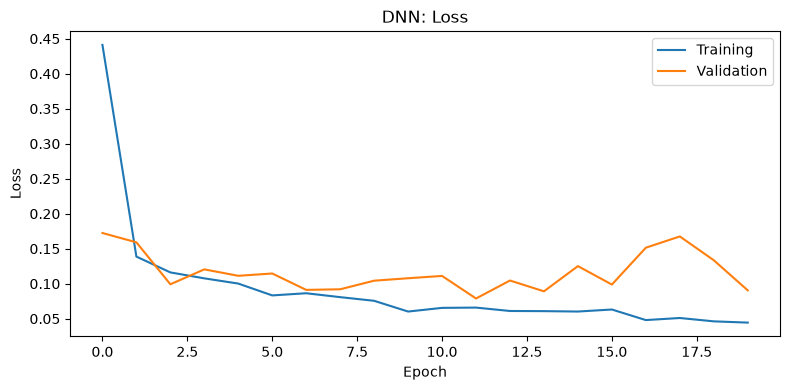

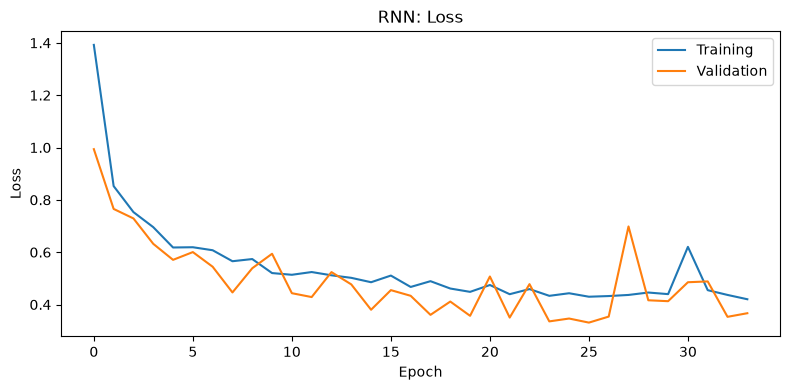

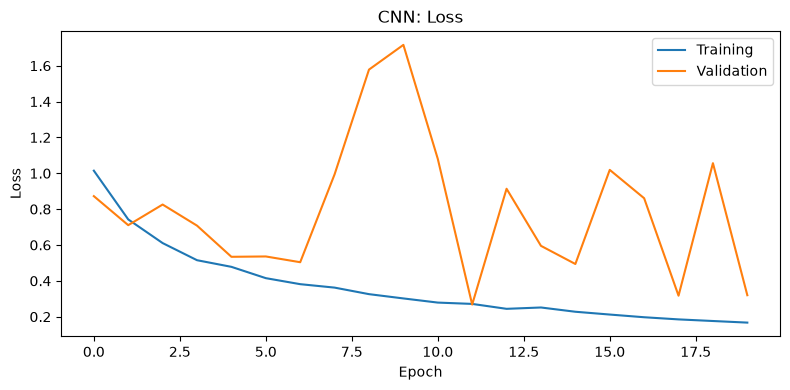

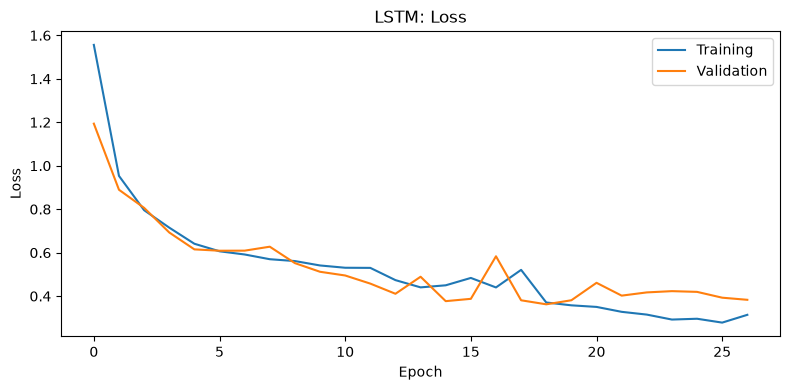

In [12]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Training")
    plt.plot(history["val_loss"], label="Validation")
    plt.title(f"{name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

#  Accuracy Curves

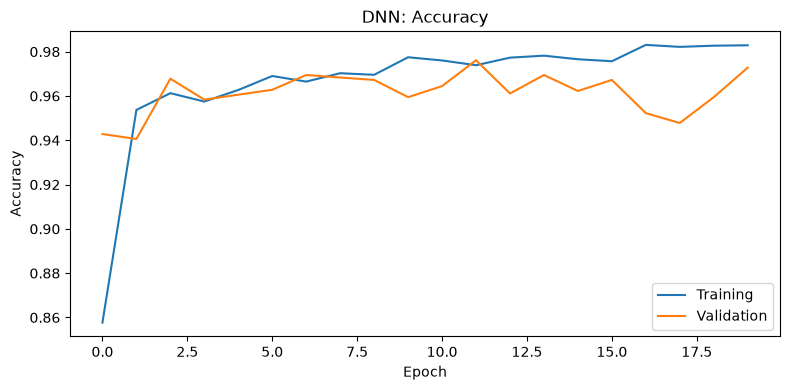

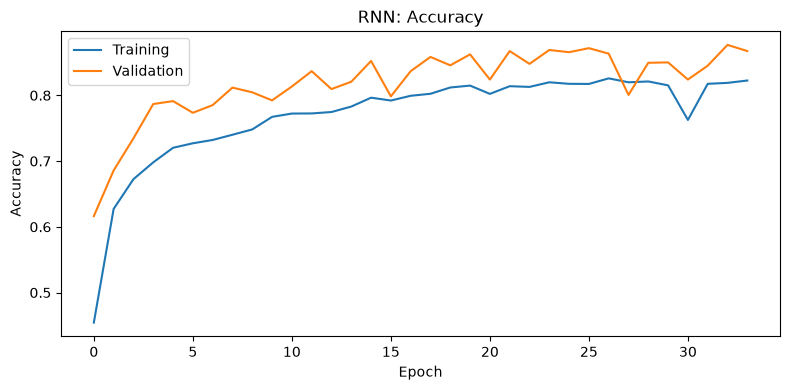

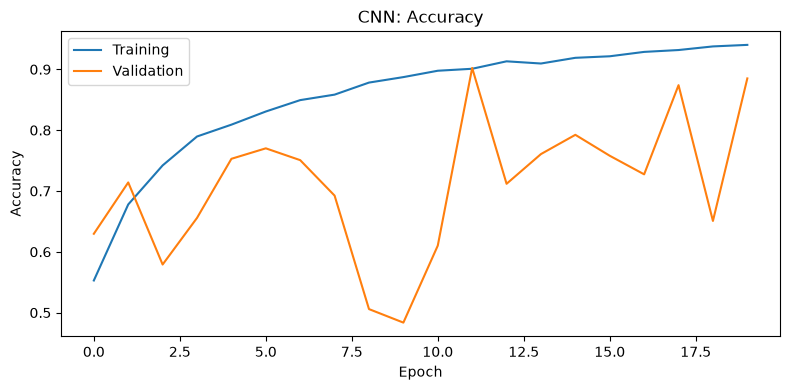

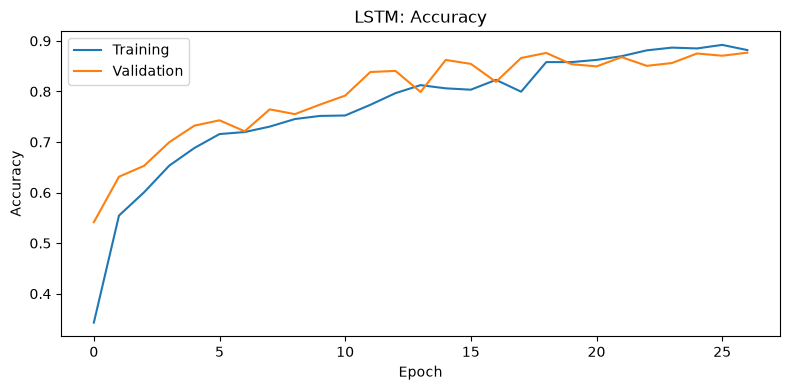

In [13]:
for name, result in training_results.items():
    history = result["history"]

    plt.figure(figsize=(8, 4))
    plt.plot(history["train_accuracy"], label="Training")
    plt.plot(history["val_accuracy"], label="Validation")
    plt.title(f"{name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Training behavior analysis

For each architecture explain:

- convergence speed;
- overfitting;
- underfitting;
- stability;
- early stopping;
- train/validation gap.

**TODO:** Write add your analysis in ypur report.

# Final Test Evaluation



Report:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Weighted F1
- Per-class metrics

In [14]:
test_results = {}

for name, model in trained_models.items():
    test_results[name] = evaluate_model(
        model,
        X_test,
        y_test,
    )

comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["macro_precision"],
        "Macro Recall": result["macro_recall"],
        "Macro F1": result["macro_f1"],
        "Weighted F1": result["weighted_f1"],
    }
    for name, result in test_results.items()
])

comparison_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DNN,0.952494,0.954167,0.951017,0.951987,0.952383
1,RNN,0.764167,0.759421,0.754153,0.755682,0.765043
2,CNN,0.848660,0.863229,0.848743,0.845336,0.848577
3,LSTM,0.791313,0.794263,0.785045,0.786784,0.791866


# Per-Class Classification Reports

In [15]:
for name, result in test_results.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print(
        classification_report(
            y_test,
            result["predictions"],
            target_names=class_names,
            digits=4,
        )
    )


DNN
                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.9518    0.8839    0.9166       491
          STANDING     0.8995    0.9586    0.9281       532
           WALKING     0.9352    0.9899    0.9618       496
WALKING_DOWNSTAIRS     0.9775    0.9310    0.9537       420
  WALKING_UPSTAIRS     0.9610    0.9427    0.9518       471

          accuracy                         0.9525      2947
         macro avg     0.9542    0.9510    0.9520      2947
      weighted avg     0.9535    0.9525    0.9524      2947


RNN
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9497    0.9742       537
           SITTING     0.8527    0.7780    0.8136       491
          STANDING     0.8070    0.8722    0.8383       532
           WALKING     0.6219    0.6996    0.6584       496
WALKING_DOWNSTAIRS     0.5918    0.5524    0.5714       420
  WALKING_UPSTAIRS     0.6

# Confusion Matrices

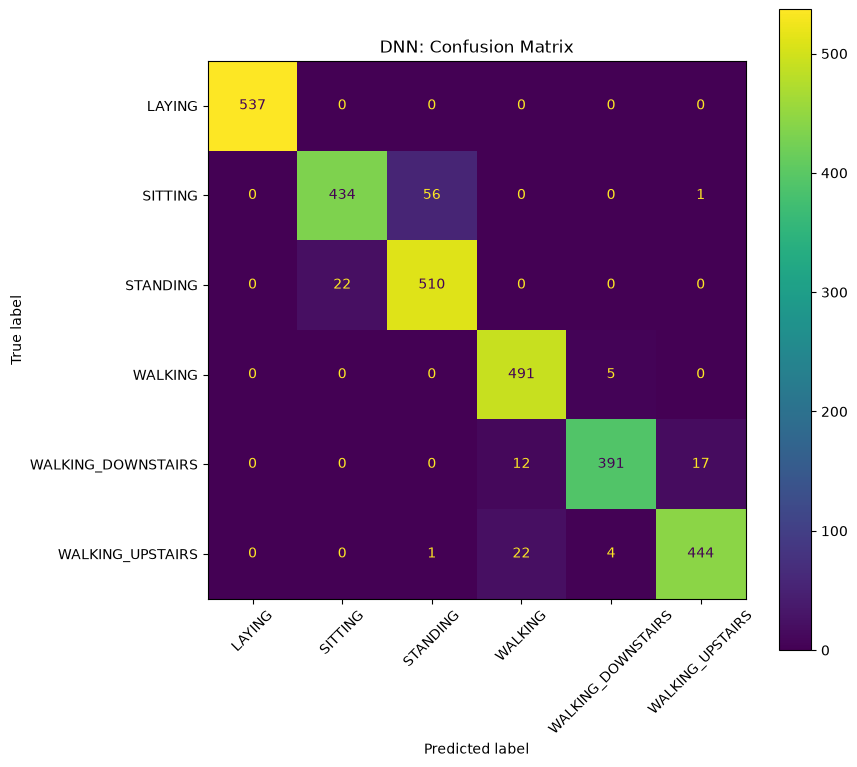

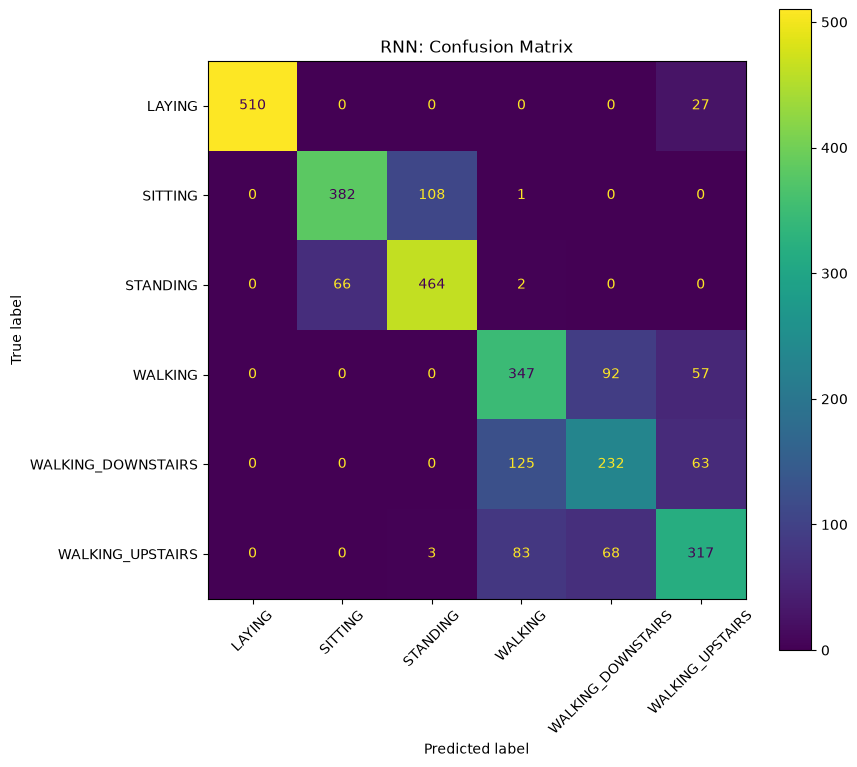

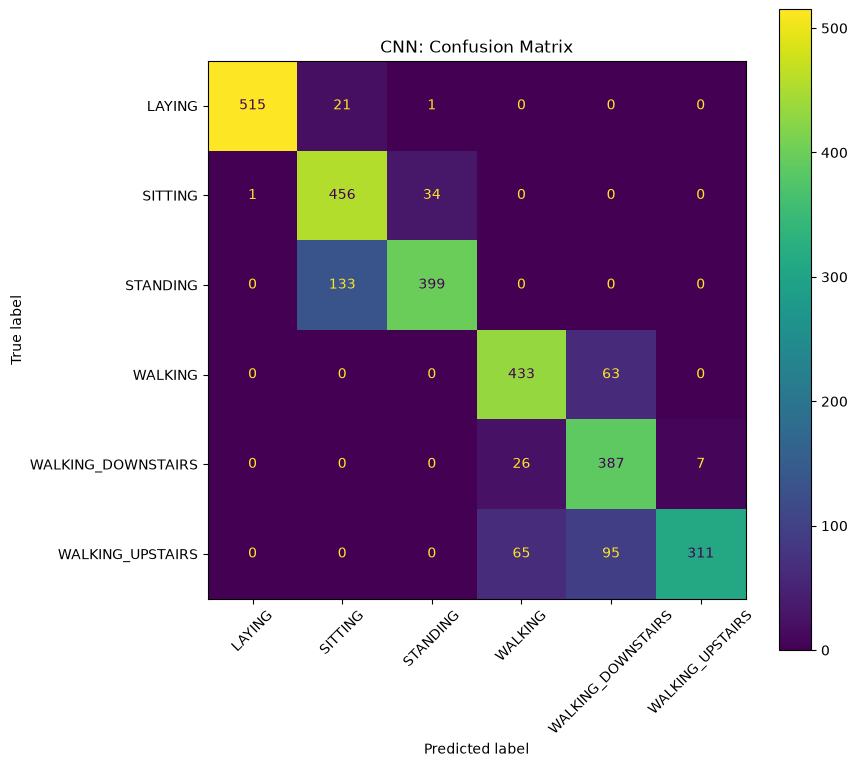

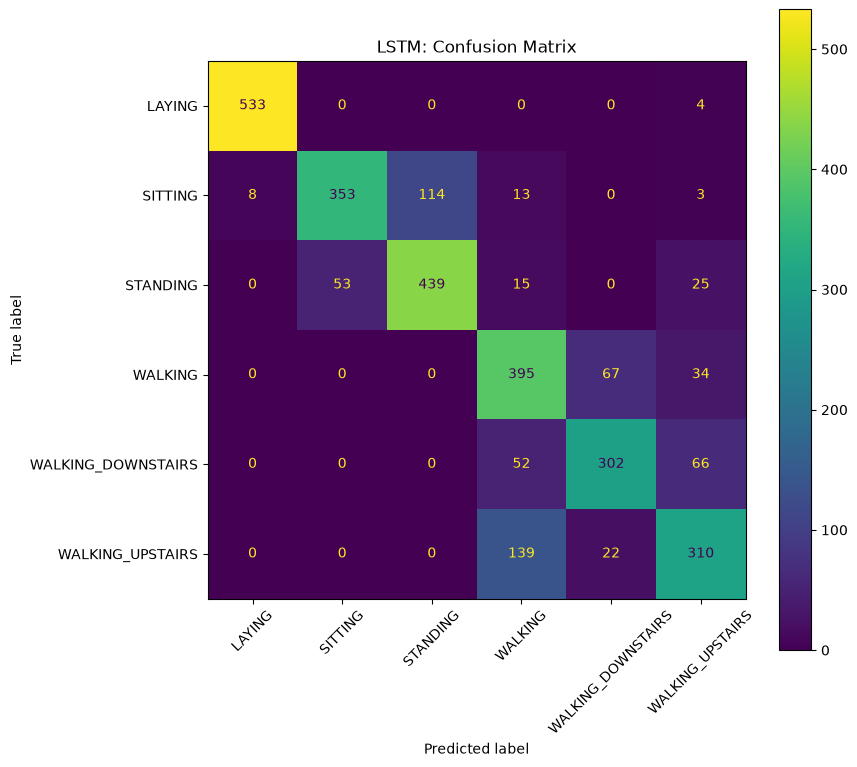

In [16]:
for name, result in test_results.items():
    cm = confusion_matrix(
        y_test,
        result["predictions"],
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )

    fig, ax = plt.subplots(figsize=(9, 8))
    disp.plot(ax=ax, xticks_rotation=45)
    plt.title(f"{name}: Confusion Matrix")
    plt.tight_layout()
    plt.show()

### Activity-specific error analysis

Explain in ypur report:

- whether recurrent models make similar errors.
- whether CNN differs from RNN/LSTM.
- whether flattening disadvantages the DNN.


# Trainable Parameter Counts

In [17]:
parameter_counts = {
    name: count_parameters(model)
    for name, model in trained_models.items()
}

parameter_df = pd.DataFrame({
    "Model": list(parameter_counts.keys()),
    "Parameters": list(parameter_counts.values()),
})

parameter_df

,Model,Parameters
0,DNN,178310
1,RNN,4678
2,CNN,52806
3,LSTM,17542


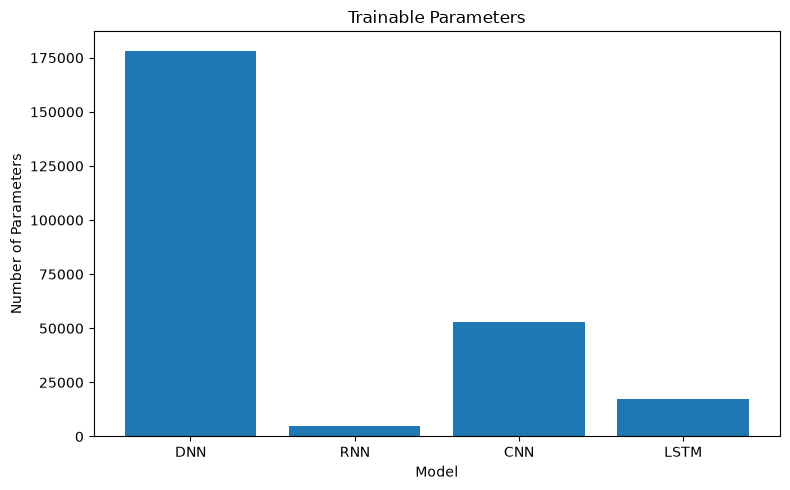

In [18]:
plt.figure(figsize=(8, 5))
plt.bar(parameter_df["Model"], parameter_df["Parameters"])
plt.title("Trainable Parameters")
plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.tight_layout()
plt.show()

# Training-Time Comparison

In [19]:
training_time_df = pd.DataFrame([
    {
        "Model": name,
        "Training Time": result["training_time"],
        "Epochs": result["epochs_completed"],
        "Average Time / Epoch": (
            result["training_time"] /
            max(result["epochs_completed"], 1)
        ),
    }
    for name, result in training_results.items()
])

training_time_df

,Model,Training Time,Epochs,Average Time / Epoch
0,DNN,6.343876,20,0.317194
1,RNN,9.657365,34,0.284040
2,CNN,9.152257,20,0.457613
3,LSTM,11.263319,27,0.417160


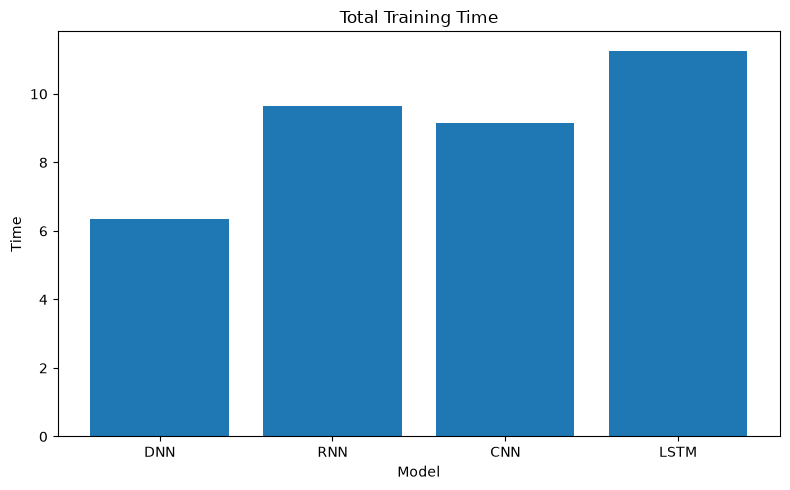

In [20]:
plt.figure(figsize=(8, 5))
plt.bar(
    training_time_df["Model"],
    training_time_df["Training Time"],
)
plt.title("Total Training Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Inference-Time Comparison

In [21]:
inference_times = {
    name: measure_inference_time(model, X_test)
    for name, model in trained_models.items()
}

inference_df = pd.DataFrame({
    "Model": list(inference_times.keys()),
    "Inference Time": list(inference_times.values()),
})

inference_df

,Model,Inference Time
0,DNN,0.004299
1,RNN,0.020490
2,CNN,0.043014
3,LSTM,0.043284


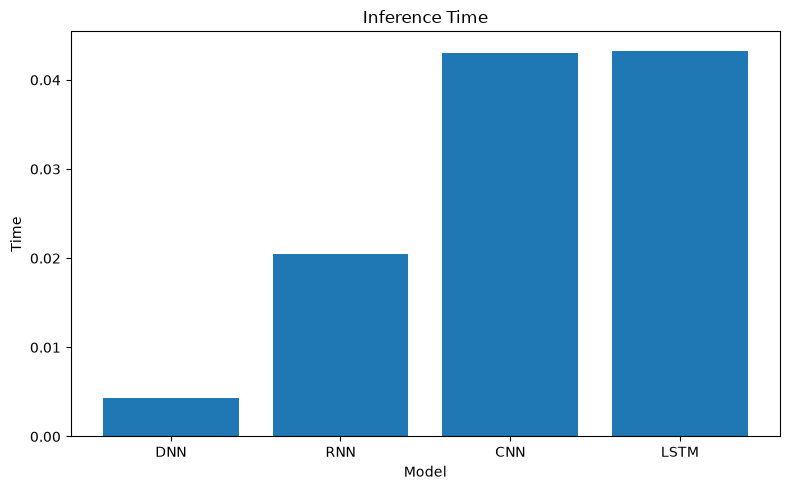

In [22]:
plt.figure(figsize=(8, 5))
plt.bar(
    inference_df["Model"],
    inference_df["Inference Time"],
)
plt.title("Inference Time")
plt.xlabel("Model")
plt.ylabel("Time")
plt.tight_layout()
plt.show()

# Complete Model Comparison

In [23]:
final_comparison = comparison_df.copy()

final_comparison["Parameters"] = (
    final_comparison["Model"].map(parameter_counts)
)

final_comparison["Training Time"] = (
    final_comparison["Model"].map({
        name: result["training_time"]
        for name, result in training_results.items()
    })
)

final_comparison["Inference Time"] = (
    final_comparison["Model"].map(inference_times)
)

final_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Parameters,Training Time,Inference Time
0,DNN,0.952494,0.954167,0.951017,0.951987,0.952383,178310,6.343876,0.004299
1,RNN,0.764167,0.759421,0.754153,0.755682,0.765043,4678,9.657365,0.020490
2,CNN,0.848660,0.863229,0.848743,0.845336,0.848577,52806,9.152257,0.043014
3,LSTM,0.791313,0.794263,0.785045,0.786784,0.791866,17542,11.263319,0.043284


# Predictive-Metric Comparison

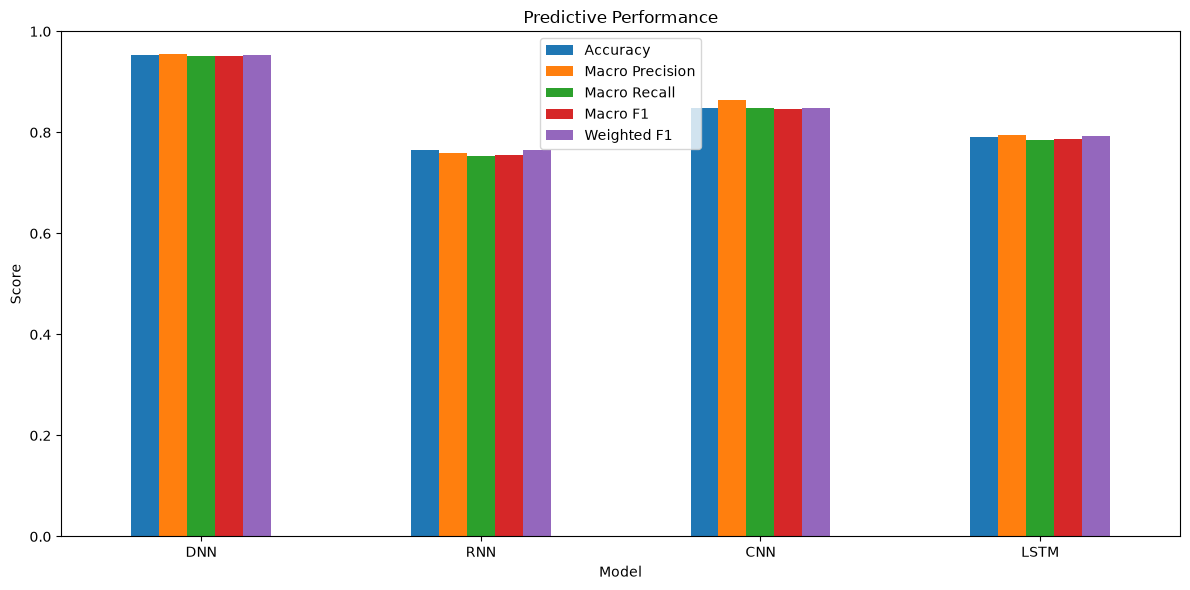

In [24]:
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
]

final_comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Predictive Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Performance vs Computational Cost

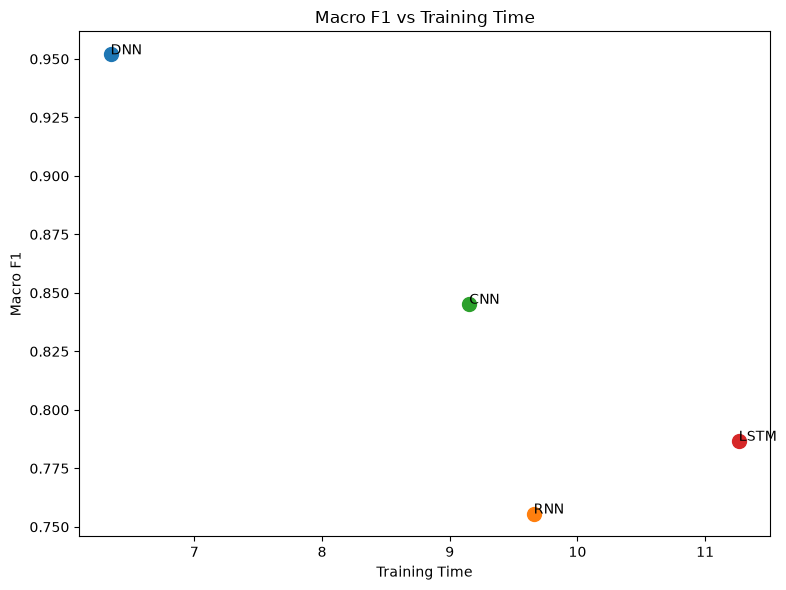

In [25]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Training Time"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Training Time"], row["Macro F1"]),
    )

plt.xlabel("Training Time")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Training Time")
plt.tight_layout()
plt.show()

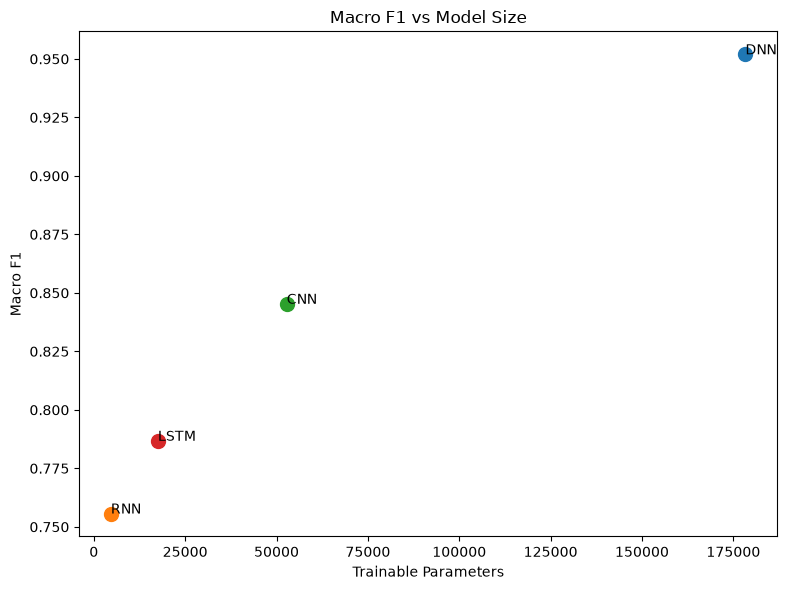

In [26]:
plt.figure(figsize=(8, 6))

for _, row in final_comparison.iterrows():
    plt.scatter(
        row["Parameters"],
        row["Macro F1"],
        s=100,
    )
    plt.annotate(
        row["Model"],
        (row["Parameters"], row["Macro F1"]),
    )

plt.xlabel("Trainable Parameters")
plt.ylabel("Macro F1")
plt.title("Macro F1 vs Model Size")
plt.tight_layout()
plt.show()

### Performance/cost discussion

Does increased architectural complexity produce a meaningful performance improvement relative to its computational cost?

**TODO:** Add your analysis in your report.

# Repeated Experiments: Three Random Seeds

Run the main comparison with at least:

```python
SEEDS = [1, 42, 123]
```

Instantiate a **new model** for every run.

Do not reuse previously trained weights.

In [27]:
SEEDS = [1, 42, 123]

seed_experiment_results = []

# TODO:
#
# for seed in SEEDS:
#     1. set_seed(seed)
#     2. instantiate fresh DNN/RNN/CNN/LSTM objects
#     3. train each model
#     4. evaluate it
#     5. record:
#        - Seed
#        - Model
#        - Accuracy
#        - Macro F1
#        - Weighted F1
#        - Training Time
#        - Parameters
#



# Aggregate Repeated Runs

In [28]:
seed_df = pd.DataFrame(seed_experiment_results)
seed_df

""


In [29]:
if not seed_df.empty:
    seed_summary = (
        seed_df
        .groupby("Model")
        .agg({
            "Accuracy": ["mean", "std"],
            "Macro F1": ["mean", "std"],
            "Weighted F1": ["mean", "std"],
            "Training Time": ["mean", "std"],
        })
    )

    display(seed_summary)
else:
    print("Complete the repeated-seed experiment first.")

Complete the repeated-seed experiment first.


### Discuss


- variability across seeds.
- whether architecture comparisons remain consistent.
- whether a conclusion based on only one run would be reliable.

**TODO:** Enrich your report.

#  Hyperparameter Experiment

Perform at least one of the following experiment.

Examples:

- DNN hidden dimension or dropout;
- RNN hidden size;
- CNN kernel size;
- CNN filter count;
- LSTM hidden size;
- batch size;
- learning rate.

Change one factor and keep other important conditions fixed.

In [30]:
experiment_values = [32, 64, 128, 256]
controlled_experiment_results = []

for value in experiment_values:
    # TODO:
    # - instantiate a fresh selected model
    # - use `value` for the selected hyperparameter
    # - train
    # - evaluate
    # - record predictive metrics, time and parameters
    pass

controlled_df = pd.DataFrame(controlled_experiment_results)
controlled_df

""


### Controlled-experiment discussion

Explain:

- the parameter selected.
- why it was selected.
- effect on predictive performance.
- effect on computational cost.
- whether larger/more complex settings consistently improved generalization.

**TODO:** Make your report count!

# Save Experimental Results

In [31]:
metrics_dir = RESULTS_DIR / "metrics"
figures_dir = RESULTS_DIR / "figures"
models_dir = RESULTS_DIR / "models"

metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

for name, model in trained_models.items():
    torch.save(model.state_dict(), models_dir / f"{name.lower()}.pt")

final_comparison.to_csv(
    metrics_dir / "model_comparison.csv",
    index=False,
)

if "seed_df" in globals() and not seed_df.empty:
    seed_df.to_csv(
        metrics_dir / "seed_results.csv",
        index=False,
    )

if "controlled_df" in globals() and not controlled_df.empty:
    controlled_df.to_csv(
        metrics_dir / "controlled_experiment.csv",
        index=False,
    )